# Predicting ASD using Deep Learning

## 1. Original vs Enhanched Images

In [17]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [26]:
import pandas as pd
import json

# Load the data from JSON
with open('/content/drive/MyDrive/ASD Level/Metadata/data.json', 'r') as f:
    data_json = json.load(f)

# Convert the 'TCImages' part of the JSON to a DataFrame
df = pd.DataFrame(data_json['TSImages'])
df = df.sort_values('ParticipantID').reset_index(drop = True)

# Add the 'Label' column based on the CARS value
df['Label'] = df['CARS'].apply(lambda x: 0 if x < 30 else 1)

from sklearn.model_selection import train_test_split

# Separate the dataset into the two classes
df_class_0 = df[df['Label'] == 0]
df_class_1 = df[df['Label'] == 1]

# Allocate 10 samples from class 0 to the test set
test_class_0, train_class_0 = train_test_split(df_class_0, test_size=len(df_class_0) - 10, random_state=42, stratify=df_class_0['Label'])

# Allocate 33 samples from class 1 to the test set
test_class_1, train_class_1 = train_test_split(df_class_1, test_size=len(df_class_1) - 33, random_state=42, stratify=df_class_1['Label'])

# Combine the test sets
test_df = pd.concat([test_class_0, test_class_1])

# Combine the remaining samples to form the training set
train_df = pd.concat([train_class_0, train_class_1])

# Shuffle the train and test sets to ensure random distribution
train_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)
test_df = test_df.sample(frac=1, random_state=42).reset_index(drop=True)


In [29]:
len(test_df)/len(train_df)

0.24431818181818182

### Original Images

In [19]:
import os
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

class TSImagesDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None):
        self.dataframe = dataframe
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_name = os.path.join(self.img_dir, self.dataframe.iloc[idx, 0])
        image = Image.open(img_name).convert('RGB')
        label = self.dataframe.iloc[idx, -1]

        if self.transform:
            image = self.transform(image)

        return image, label

# Define the image directory and transformations
img_dir = '/content/drive/MyDrive/ASD Level/Images/TSImages'
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # Resize images to 100x100 pixels
    transforms.ToTensor()  # Convert images to PyTorch tensors
])

# Create the training and testing datasets
train_dataset = TSImagesDataset(dataframe=train_df, img_dir=img_dir, transform=transform)
test_dataset = TSImagesDataset(dataframe=test_df, img_dir=img_dir, transform=transform)

# Create DataLoaders for training and testing sets
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)


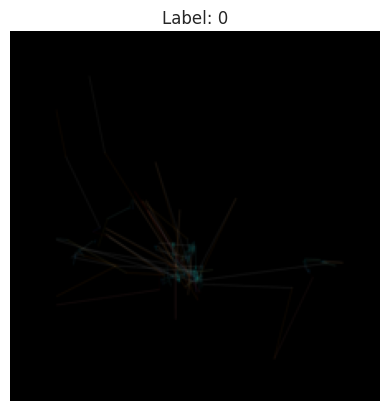

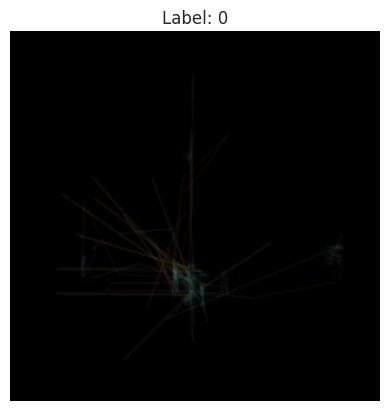

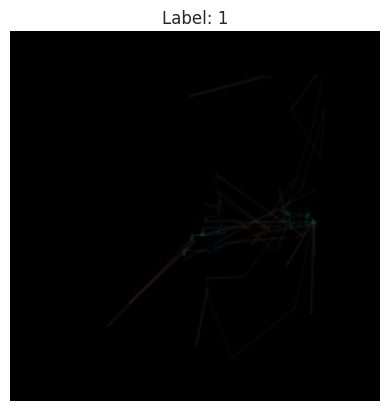

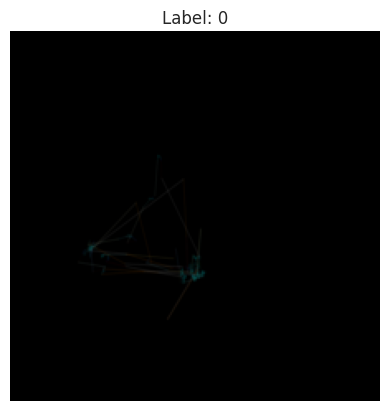

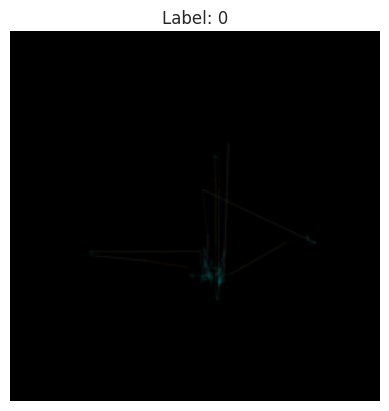

In [20]:
import matplotlib.pyplot as plt
import torch

# Get the first 5 images from the dataset
for i in range(5):
    image, label = train_dataset[i]

    # Convert the image tensor to a numpy array if using PyTorch transforms
    if isinstance(image, torch.Tensor):
        image = image.permute(1, 2, 0).numpy()

    # Display the image
    plt.figure()
    plt.imshow(image)
    plt.title(f'Label: {label}')
    plt.axis('off')
    plt.show()


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        # Define the layers of the CNN
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)  # Changed input channels to 3 for RGB
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.dropout = nn.Dropout(0.4)
        self.fc1 = nn.Linear(128 * 28 * 28, 512)
        self.fc2 = nn.Linear(512, 2)  # Assuming binary classification (ASD vs TD)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # Apply convolution -> ReLU -> Pooling
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = x.view(-1, 128 * 28 * 28)  # Flatten the tensor
        x = F.relu(self.fc1(x))  # Fully connected layer -> ReLU
        x = self.dropout(x)
        x = self.fc2(x)  # Final output layer
        return x

# Instantiate the model
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = CNN().to(device)

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 100

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for data in train_dataloader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)  # Use .to(device) instead of .cuda()

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Calculate running loss and accuracy
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_dataloader):.4f}, Accuracy: {100 * correct / total:.2f}%")


In [ ]:
import torch
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns

# Set the model to evaluation mode
model.eval()

# Initialize lists to store true labels and predictions
all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for data in test_dataloader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)

        # Get predicted probabilities by applying softmax
        probabilities = torch.softmax(outputs, dim=1)[:, 1]  # Get probabilities for class 1
        _, predicted = torch.max(outputs.data, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

# Convert lists to numpy arrays
all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

# Calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average='binary')
recall = recall_score(all_labels, all_predictions, average='binary')
f1 = f1_score(all_labels, all_predictions, average='binary')

# Print the metrics
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")

# Calculate the confusion matrix
conf_matrix = confusion_matrix(all_labels, all_predictions)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['TD', 'ASD'], yticklabels=['TD', 'ASD'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Calculate the ROC curve and AUC
fpr, tpr, thresholds = roc_curve(all_labels, all_probabilities)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

# Find the best threshold based on maximizing F1 score
best_threshold = thresholds[np.argmax(2 * (tpr * (1 - fpr)) / (tpr + (1 - fpr)))]

# Adjust predictions based on the best threshold
adjusted_predictions = (all_probabilities >= best_threshold).astype(int)

# Calculate adjusted metrics
adjusted_accuracy = accuracy_score(all_labels, adjusted_predictions)
adjusted_precision = precision_score(all_labels, adjusted_predictions)
adjusted_recall = recall_score(all_labels, adjusted_predictions)
adjusted_f1 = f1_score(all_labels, adjusted_predictions)

# Print the adjusted metrics and the best threshold
print(f"Best Threshold: {best_threshold:.4f}")
print(f"Adjusted Accuracy: {adjusted_accuracy:.4f}")
print(f"Adjusted Precision: {adjusted_precision:.4f}")
print(f"Adjusted Recall: {adjusted_recall:.4f}")
print(f"Adjusted F1 Score: {adjusted_f1:.4f}")


### Enhanched Images

In [21]:
from PIL import ImageEnhance, ImageOps

class EnhanceImage:
    def __init__(self, brightness_factor=1.5, contrast_factor=1.5, exposure_factor=1.2,
                 shadow_factor=0.8, saturation_factor=1.5, temperature_factor=1.2):
        self.brightness_factor = brightness_factor
        self.contrast_factor = contrast_factor
        self.exposure_factor = exposure_factor
        self.shadow_factor = shadow_factor
        self.saturation_factor = saturation_factor
        self.temperature_factor = temperature_factor

    def __call__(self, image):
        # Convert PyTorch tensor to PIL image if necessary
        if isinstance(image, torch.Tensor):
            image = transforms.ToPILImage()(image)

        # Enhance the brightness
        enhancer = ImageEnhance.Brightness(image)
        image = enhancer.enhance(self.brightness_factor)

        # Enhance the contrast
        enhancer = ImageEnhance.Contrast(image)
        image = enhancer.enhance(self.contrast_factor)

        # Increase exposure (simulated by increasing brightness)
        enhancer = ImageEnhance.Brightness(image)
        image = enhancer.enhance(self.exposure_factor)

        # Increase shadows (reduce brightness slightly)
        enhancer = ImageEnhance.Brightness(image)
        shadowed_image = enhancer.enhance(self.shadow_factor)
        image = Image.blend(image, shadowed_image, alpha=0.5)

        # Increase saturation
        enhancer = ImageEnhance.Color(image)
        image = enhancer.enhance(self.saturation_factor)

        # Adjust temperature (simulated by adding a warm filter)
        red, green, blue = image.split()
        red = red.point(lambda p: p * self.temperature_factor)
        image = Image.merge("RGB", (red, green, blue))

        return image

class TSImagesDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None, enhance_image=None):
        self.dataframe = dataframe
        self.img_dir = img_dir
        self.transform = transform
        self.enhance_image = enhance_image

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_name = os.path.join(self.img_dir, self.dataframe.iloc[idx, 0])
        image = Image.open(img_name).convert('RGB')
        label = self.dataframe.iloc[idx, -1]

        # Apply the enhancement if provided
        if self.enhance_image:
            image = self.enhance_image(image)

        # Apply other transformations if provided
        if self.transform:
            image = self.transform(image)

        return image, label

# Assuming you already have the enhancer configured
enhancer = EnhanceImage(
    brightness_factor=1.5,
    contrast_factor=1.5,
    exposure_factor=1.2,
    shadow_factor=0.8,
    saturation_factor=1.5,
    temperature_factor=1.2
)

# Create the training and testing datasets
train_dataset = TSImagesDataset(dataframe=train_df, img_dir=img_dir, transform=transform, enhance_image=enhancer)
test_dataset = TSImagesDataset(dataframe=test_df, img_dir=img_dir, transform=transform, enhance_image=enhancer)

# Create DataLoaders for training and testing sets
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)

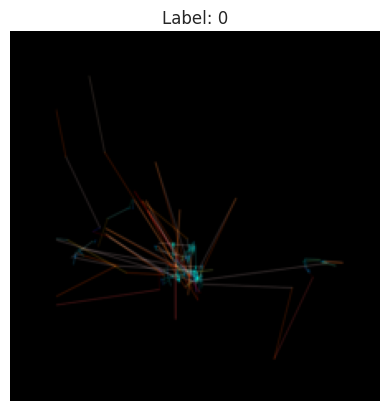

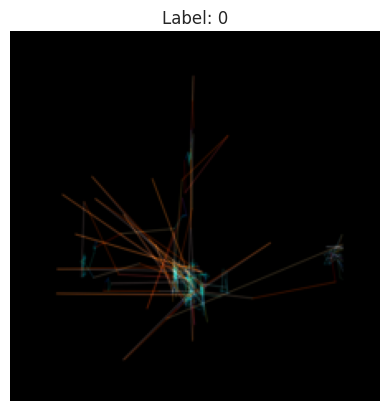

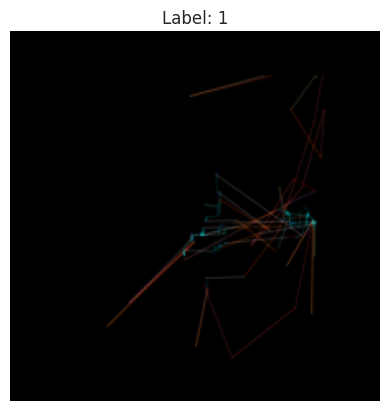

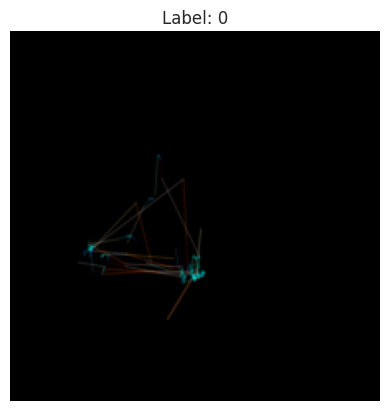

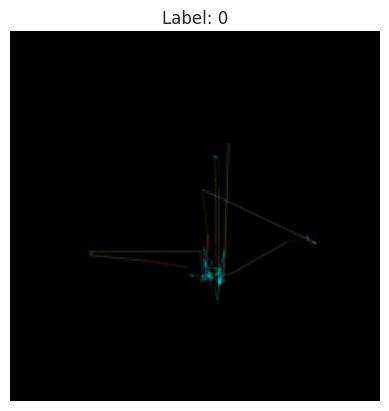

In [22]:
import matplotlib.pyplot as plt
import torch

# Get the first 5 images from the dataset
for i in range(5):
    image, label = train_dataset[i]

    # Convert the image tensor to a numpy array if using PyTorch transforms
    if isinstance(image, torch.Tensor):
        image = image.permute(1, 2, 0).numpy()

    # Display the image
    plt.figure()
    plt.imshow(image)
    plt.title(f'Label: {label}')
    plt.axis('off')
    plt.show()


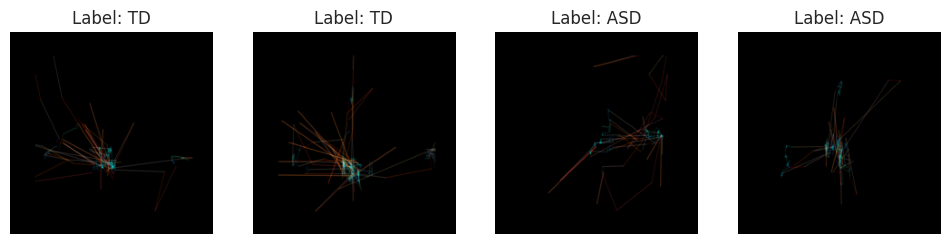

In [25]:
import matplotlib.pyplot as plt
import torch

# Define the label mapping
label_mapping = {0: 'TD', 1: 'ASD'}

# Create a figure with 1 row and 4 columns
fig, axes = plt.subplots(1, 4, figsize=(12, 5))

# Counters to track the number of images shown for each label
count_td = 0
count_asd = 0

# Iterate over the dataset to find and display 2 TD and 2 ASD images
i = 0
while count_td < 2 or count_asd < 2:
    image, label = train_dataset[i]

    # Convert the image tensor to a numpy array if using PyTorch transforms
    if isinstance(image, torch.Tensor):
        image = image.permute(1, 2, 0).numpy()

    # Check the label and display the image if it fits the criteria
    if label == 0 and count_td < 2:
        axes[count_td + count_asd].imshow(image)
        axes[count_td + count_asd].set_title(f'Label: {label_mapping[label]}')
        axes[count_td + count_asd].axis('off')
        count_td += 1
    elif label == 1 and count_asd < 2:
        axes[count_td + count_asd].imshow(image)
        axes[count_td + count_asd].set_title(f'Label: {label_mapping[label]}')
        axes[count_td + count_asd].axis('off')
        count_asd += 1

    i += 1

# Display the figure
plt.show()


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        # Define the layers of the CNN
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)  # Changed input channels to 3 for RGB
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.dropout = nn.Dropout(0.4)
        self.fc1 = nn.Linear(128 * 28 * 28, 512)
        self.fc2 = nn.Linear(512, 2)  # Assuming binary classification (ASD vs TD)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # Apply convolution -> ReLU -> Pooling
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = x.view(-1, 128 * 28 * 28)  # Flatten the tensor
        x = F.relu(self.fc1(x))  # Fully connected layer -> ReLU
        x = self.dropout(x)
        x = self.fc2(x)  # Final output layer
        return x

# Instantiate the model
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = CNN().to(device)

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 100

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for data in train_dataloader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)  # Use .to(device) instead of .cuda()

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Calculate running loss and accuracy
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_dataloader):.4f}, Accuracy: {100 * correct / total:.2f}%")


In [ ]:
import torch
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns

# Set the model to evaluation mode
model.eval()

# Initialize lists to store true labels and predictions
all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for data in test_dataloader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)

        # Get predicted probabilities by applying softmax
        probabilities = torch.softmax(outputs, dim=1)[:, 1]  # Get probabilities for class 1
        _, predicted = torch.max(outputs.data, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

# Convert lists to numpy arrays
all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

# Calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average='binary')
recall = recall_score(all_labels, all_predictions, average='binary')
f1 = f1_score(all_labels, all_predictions, average='binary')

# Print the metrics
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")

# Calculate the confusion matrix
conf_matrix = confusion_matrix(all_labels, all_predictions)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['TD', 'ASD'], yticklabels=['TD', 'ASD'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Calculate the ROC curve and AUC
fpr, tpr, thresholds = roc_curve(all_labels, all_probabilities)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

# Find the best threshold based on maximizing F1 score
best_threshold = thresholds[np.argmax(2 * (tpr * (1 - fpr)) / (tpr + (1 - fpr)))]

# Adjust predictions based on the best threshold
adjusted_predictions = (all_probabilities >= best_threshold).astype(int)

# Calculate adjusted metrics
adjusted_accuracy = accuracy_score(all_labels, adjusted_predictions)
adjusted_precision = precision_score(all_labels, adjusted_predictions)
adjusted_recall = recall_score(all_labels, adjusted_predictions)
adjusted_f1 = f1_score(all_labels, adjusted_predictions)

# Print the adjusted metrics and the best threshold
print(f"Best Threshold: {best_threshold:.4f}")
print(f"Adjusted Accuracy: {adjusted_accuracy:.4f}")
print(f"Adjusted Precision: {adjusted_precision:.4f}")
print(f"Adjusted Recall: {adjusted_recall:.4f}")
print(f"Adjusted F1 Score: {adjusted_f1:.4f}")


## Grey Scale vs RGB Scale

In [ ]:
from PIL import ImageEnhance, ImageOps, Image

class EnhanceImage:
    def __init__(self, brightness_factor=1.5, contrast_factor=1.5, exposure_factor=1.2,
                 shadow_factor=0.8, saturation_factor=1.5, temperature_factor=1.2):
        self.brightness_factor = brightness_factor
        self.contrast_factor = contrast_factor
        self.exposure_factor = exposure_factor
        self.shadow_factor = shadow_factor
        self.saturation_factor = saturation_factor
        self.temperature_factor = temperature_factor

    def __call__(self, image):
        # Convert PyTorch tensor to PIL image if necessary
        if isinstance(image, torch.Tensor):
            image = transforms.ToPILImage()(image)

        # Convert image to grayscale
        image = ImageOps.grayscale(image)

        # Enhance the brightness
        enhancer = ImageEnhance.Brightness(image)
        image = enhancer.enhance(self.brightness_factor)

        # Enhance the contrast
        enhancer = ImageEnhance.Contrast(image)
        image = enhancer.enhance(self.contrast_factor)

        # Increase exposure (simulated by increasing brightness)
        enhancer = ImageEnhance.Brightness(image)
        image = enhancer.enhance(self.exposure_factor)

        # Increase shadows (reduce brightness slightly)
        enhancer = ImageEnhance.Brightness(image)
        shadowed_image = enhancer.enhance(self.shadow_factor)
        image = Image.blend(image, shadowed_image, alpha=0.5)

        return image

class TSImagesDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None, enhance_image=None):
        self.dataframe = dataframe
        self.img_dir = img_dir
        self.transform = transform
        self.enhance_image = enhance_image

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_name = os.path.join(self.img_dir, self.dataframe.iloc[idx, 0])
        image = Image.open(img_name).convert('L')  # Convert image to grayscale
        label = self.dataframe.iloc[idx, -1]

        # Apply the enhancement if provided
        if self.enhance_image:
            image = self.enhance_image(image)

        # Apply other transformations if provided
        if self.transform:
            image = self.transform(image)

        return image, label

# Assuming you already have the enhancer configured
enhancer = EnhanceImage(
    brightness_factor=1.5,
    contrast_factor=1.5,
    exposure_factor=1.2,
    shadow_factor=0.8,
    saturation_factor=1.5,  # This won't affect grayscale images but can be left in place
    temperature_factor=1.2  # This also won't affect grayscale images
)

# Create the training and testing datasets
train_dataset = TSImagesDataset(dataframe=train_df, img_dir=img_dir, transform=transform, enhance_image=enhancer)
test_dataset = TSImagesDataset(dataframe=test_df, img_dir=img_dir, transform=transform, enhance_image=enhancer)

# Create DataLoaders for training and testing sets
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)


In [ ]:
import matplotlib.pyplot as plt
import torch

# Get the first 5 images from the dataset
for i in range(1):
    image, label = train_dataset[i]

    # Check if the image is a tensor and convert it to numpy array if needed
    if isinstance(image, torch.Tensor):
        image = image.squeeze().numpy()  # Remove any singleton dimensions (like a channel dimension)

    # Display the image
    plt.figure()
    plt.imshow(image, cmap='gray')  # Use 'gray' colormap to ensure it displays as grayscale
    plt.title(f'Label: {label}')
    plt.axis('off')
    plt.show()


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        # Define the layers of the CNN
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1)  # Input channels set to 1 for grayscale
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)
        self.dropout = nn.Dropout(0.4)
        self.fc1 = nn.Linear(128 * 28 * 28, 512)
        self.fc2 = nn.Linear(512, 2)  # Assuming binary classification (ASD vs TD)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # Apply convolution -> ReLU -> Pooling
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = x.view(-1, 128 * 28 * 28)  # Flatten the tensor
        x = F.relu(self.fc1(x))  # Fully connected layer -> ReLU
        x = self.dropout(x)
        x = self.fc2(x)  # Final output layer
        return x

# Instantiate the model
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = CNN().to(device)

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 100

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for data in train_dataloader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)  # Use .to(device) instead of .cuda()

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Calculate running loss and accuracy
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_dataloader):.4f}, Accuracy: {100 * correct / total:.2f}%")


In [ ]:
import torch
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns

# Set the model to evaluation mode
model.eval()

# Initialize lists to store true labels and predictions
all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for data in test_dataloader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)

        # Get predicted probabilities by applying softmax
        probabilities = torch.softmax(outputs, dim=1)[:, 1]  # Get probabilities for class 1
        _, predicted = torch.max(outputs.data, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

# Convert lists to numpy arrays
all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

# Calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average='binary')
recall = recall_score(all_labels, all_predictions, average='binary')
f1 = f1_score(all_labels, all_predictions, average='binary')

# Print the metrics
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")

# Calculate the confusion matrix
conf_matrix = confusion_matrix(all_labels, all_predictions)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['TD', 'ASD'], yticklabels=['TD', 'ASD'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Calculate the ROC curve and AUC
fpr, tpr, thresholds = roc_curve(all_labels, all_probabilities)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

# Find the best threshold based on maximizing F1 score
best_threshold = thresholds[np.argmax(2 * (tpr * (1 - fpr)) / (tpr + (1 - fpr)))]

# Adjust predictions based on the best threshold
adjusted_predictions = (all_probabilities >= best_threshold).astype(int)

# Calculate adjusted metrics
adjusted_accuracy = accuracy_score(all_labels, adjusted_predictions)
adjusted_precision = precision_score(all_labels, adjusted_predictions)
adjusted_recall = recall_score(all_labels, adjusted_predictions)
adjusted_f1 = f1_score(all_labels, adjusted_predictions)

# Print the adjusted metrics and the best threshold
print(f"Best Threshold: {best_threshold:.4f}")
print(f"Adjusted Accuracy: {adjusted_accuracy:.4f}")
print(f"Adjusted Precision: {adjusted_precision:.4f}")
print(f"Adjusted Recall: {adjusted_recall:.4f}")
print(f"Adjusted F1 Score: {adjusted_f1:.4f}")


## Autoencoders

In [ ]:
# Reduce learning rate
optimizer = optim.Adam(model.parameters(), lr=0.0001)

# Adjust sparsity target and beta if necessary
sparsity_target = 0.05
beta = 3.0

# Optionally add L2 regularization (weight decay)
optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=1e-5)

# Training loop
num_epochs = 200
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for data in train_loader:
        images, _ = data  # Ignore labels
        images = images.to(device)

        # Forward pass
        outputs, encoded = model(images)

        # Calculate the reconstruction loss
        loss = criterion(outputs, images)

        # Calculate the KL divergence for sparsity
        p_hat = torch.mean(encoded, dim=0)
        kl_loss = kl_divergence(sparsity_target, p_hat).sum()

        # Combine losses
        total_loss = loss + beta * kl_loss

        # Backward pass and optimize
        optimizer.zero_grad()
        total_loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        running_loss += total_loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_loader):.4f}")

    # Validation
    model.eval()
    valid_loss = 0.0
    with torch.no_grad():
        for data in valid_loader:
            images, _ = data
            images = images.to(device)

            outputs, _ = model(images)
            loss = criterion(outputs, images)
            valid_loss += loss.item()

    print(f"Validation Loss: {valid_loss/len(valid_loader):.4f}")


In [ ]:
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

# Function to display original and reconstructed images
def show_before_after(model, dataset, num_images=5):
    model.eval()  # Set the autoencoder to evaluation mode

    with torch.no_grad():
        # Get a batch of images from the dataset
        images, _ = next(iter(DataLoader(dataset, batch_size=num_images, shuffle=True)))
        images = images.to(device)

        # Pass the images through the autoencoder to get the reconstructed images
        reconstructed, _ = model(images)  # Unpack the tuple, only keep the reconstructed images

        # Move tensors to CPU for display
        images = images.cpu()
        reconstructed = reconstructed.cpu()

        # Plot the original and reconstructed images side by side
        for i in range(num_images):
            plt.figure(figsize=(6, 3))

            # Original image
            plt.subplot(1, 2, 1)
            plt.imshow(images[i].squeeze(), cmap='gray')
            plt.title("Original")
            plt.axis('off')

            # Reconstructed image
            plt.subplot(1, 2, 2)
            plt.imshow(reconstructed[i].squeeze(), cmap='gray')
            plt.title("Reconstructed")
            plt.axis('off')

            plt.show()

# Show before and after autoencoding on the training dataset
show_before_after(model, train_dataset, num_images=5)


## Other Models

### ResNet50

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Load the pretrained ResNet50 model
model = models.resnet50(pretrained=True)

# Freeze the early layers (optional)
for param in model.parameters():
    param.requires_grad = False

# Replace the final fully connected layer to match the number of classes in your task
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)  # Assuming 2 classes (label 0 and label 1)

# Move the model to GPU if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

# Training the model
num_epochs = 100
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_dataloader):.4f}")

print("Finished Training")

# Testing the model
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for inputs, labels in test_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Accuracy of the model on the test images: {100 * correct / total:.2f}%")


/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Epoch [1/100], Loss: 0.7239
Epoch [2/100], Loss: 0.6488
Epoch [3/100], Loss: 0.6063
Epoch [4/100], Loss: 0.5729
Epoch [5/100], Loss: 0.5395
Epoch [6/100], Loss: 0.5315
Epoch [7/100], Loss: 0.5399
Epoch [8/100], Loss: 0.4720
Epoch [9/100], Loss: 0.5051
Epoch [10/100], Loss: 0.4627
Epoch [11/100], Loss: 0.4619
Epoch [12/100], Loss: 0.4626
Epoch [13/100], Loss: 0.4266
Epoch [14/100], Loss: 0.4211
Epoch [15/100], Loss: 0.4255
Epoch [16/100], Loss: 0.4158
Epoch [17/100], Loss: 0.3949
Epoch [18/100], Loss: 0.3853
Epoch [19/100], Loss: 0.3816
Epoch [20/100], Loss: 0.3732
Epoch [21/100], Loss: 0.4623
Epoch [22/100], Loss: 0.3639
Epoch [23/100], Loss: 0.3594
Epoch [24/100], Loss: 0.3648
Epoch [25/100], Loss: 0.3560
Epoch [26/100], Loss: 0.3297


In [ ]:
import torch
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns

# Set the model to evaluation mode
model.eval()

# Initialize lists to store true labels and predictions
all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for data in test_dataloader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)

        # Get predicted probabilities by applying softmax
        probabilities = torch.softmax(outputs, dim=1)[:, 1]  # Get probabilities for class 1
        _, predicted = torch.max(outputs.data, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

# Convert lists to numpy arrays
all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

# Calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average='binary')
recall = recall_score(all_labels, all_predictions, average='binary')
f1 = f1_score(all_labels, all_predictions, average='binary')

# Print the metrics
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")

# Calculate the confusion matrix
conf_matrix = confusion_matrix(all_labels, all_predictions)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['TD', 'ASD'], yticklabels=['TD', 'ASD'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Calculate the ROC curve and AUC
fpr, tpr, thresholds = roc_curve(all_labels, all_probabilities)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

# Find the best threshold based on maximizing F1 score
best_threshold = thresholds[np.argmax(2 * (tpr * (1 - fpr)) / (tpr + (1 - fpr)))]

# Adjust predictions based on the best threshold
adjusted_predictions = (all_probabilities >= best_threshold).astype(int)

# Calculate adjusted metrics
adjusted_accuracy = accuracy_score(all_labels, adjusted_predictions)
adjusted_precision = precision_score(all_labels, adjusted_predictions)
adjusted_recall = recall_score(all_labels, adjusted_predictions)
adjusted_f1 = f1_score(all_labels, adjusted_predictions)

# Print the adjusted metrics and the best threshold
print(f"Best Threshold: {best_threshold:.4f}")
print(f"Adjusted Accuracy: {adjusted_accuracy:.4f}")
print(f"Adjusted Precision: {adjusted_precision:.4f}")
print(f"Adjusted Recall: {adjusted_recall:.4f}")
print(f"Adjusted F1 Score: {adjusted_f1:.4f}")


### DenseNet121

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Load the pretrained DenseNet121 model
model = models.densenet121(pretrained=True)

# Freeze the early layers (optional)
for param in model.parameters():
    param.requires_grad = False

# Replace the final fully connected layer to match the number of classes in your task
num_ftrs = model.classifier.in_features
model.classifier = nn.Linear(num_ftrs, 2)  # Assuming 2 classes (label 0 and label 1)

# Move the model to GPU if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=0.001)

# Training the model
num_epochs = 100
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_dataloader):.4f}")

print("Finished Training")

# Testing the model
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for inputs, labels in test_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Accuracy of the model on the test images: {100 * correct / total:.2f}%")


In [ ]:
import torch
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns

# Set the model to evaluation mode
model.eval()

# Initialize lists to store true labels and predictions
all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for data in test_dataloader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)

        # Get predicted probabilities by applying softmax
        probabilities = torch.softmax(outputs, dim=1)[:, 1]  # Get probabilities for class 1
        _, predicted = torch.max(outputs.data, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

# Convert lists to numpy arrays
all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

# Calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average='binary')
recall = recall_score(all_labels, all_predictions, average='binary')
f1 = f1_score(all_labels, all_predictions, average='binary')

# Print the metrics
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")

# Calculate the confusion matrix
conf_matrix = confusion_matrix(all_labels, all_predictions)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['TD', 'ASD'], yticklabels=['TD', 'ASD'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Calculate the ROC curve and AUC
fpr, tpr, thresholds = roc_curve(all_labels, all_probabilities)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

# Find the best threshold based on maximizing F1 score
best_threshold = thresholds[np.argmax(2 * (tpr * (1 - fpr)) / (tpr + (1 - fpr)))]

# Adjust predictions based on the best threshold
adjusted_predictions = (all_probabilities >= best_threshold).astype(int)

# Calculate adjusted metrics
adjusted_accuracy = accuracy_score(all_labels, adjusted_predictions)
adjusted_precision = precision_score(all_labels, adjusted_predictions)
adjusted_recall = recall_score(all_labels, adjusted_predictions)
adjusted_f1 = f1_score(all_labels, adjusted_predictions)

# Print the adjusted metrics and the best threshold
print(f"Best Threshold: {best_threshold:.4f}")
print(f"Adjusted Accuracy: {adjusted_accuracy:.4f}")
print(f"Adjusted Precision: {adjusted_precision:.4f}")
print(f"Adjusted Recall: {adjusted_recall:.4f}")
print(f"Adjusted F1 Score: {adjusted_f1:.4f}")


### Vision Transformer

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from transformers import ViTForImageClassification, ViTFeatureExtractor
from torch.utils.data import DataLoader

# Load the pretrained ViT model from Hugging Face
model = ViTForImageClassification.from_pretrained('google/vit-base-patch16-224-in21k', num_labels=2)

# Load the feature extractor for ViT
feature_extractor = ViTFeatureExtractor.from_pretrained('google/vit-base-patch16-224-in21k')

# Move the model to GPU if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training the model
num_epochs = 100
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(pixel_values=inputs).logits
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_dataloader):.4f}")

print("Finished Training")


In [ ]:
import torch
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns

# Set the model to evaluation mode
model.eval()

# Initialize lists to store true labels and predictions
all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for data in test_dataloader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)

        # Get predicted probabilities by applying softmax
        probabilities = torch.softmax(outputs, dim=1)[:, 1]  # Get probabilities for class 1
        _, predicted = torch.max(outputs.data, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

# Convert lists to numpy arrays
all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

# Calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average='binary')
recall = recall_score(all_labels, all_predictions, average='binary')
f1 = f1_score(all_labels, all_predictions, average='binary')

# Print the metrics
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")

# Calculate the confusion matrix
conf_matrix = confusion_matrix(all_labels, all_predictions)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['TD', 'ASD'], yticklabels=['TD', 'ASD'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Calculate the ROC curve and AUC
fpr, tpr, thresholds = roc_curve(all_labels, all_probabilities)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

# Find the best threshold based on maximizing F1 score
best_threshold = thresholds[np.argmax(2 * (tpr * (1 - fpr)) / (tpr + (1 - fpr)))]

# Adjust predictions based on the best threshold
adjusted_predictions = (all_probabilities >= best_threshold).astype(int)

# Calculate adjusted metrics
adjusted_accuracy = accuracy_score(all_labels, adjusted_predictions)
adjusted_precision = precision_score(all_labels, adjusted_predictions)
adjusted_recall = recall_score(all_labels, adjusted_predictions)
adjusted_f1 = f1_score(all_labels, adjusted_predictions)

# Print the adjusted metrics and the best threshold
print(f"Best Threshold: {best_threshold:.4f}")
print(f"Adjusted Accuracy: {adjusted_accuracy:.4f}")
print(f"Adjusted Precision: {adjusted_precision:.4f}")
print(f"Adjusted Recall: {adjusted_recall:.4f}")
print(f"Adjusted F1 Score: {adjusted_f1:.4f}")


### Swin Transformer

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from transformers import SwinForImageClassification, AutoImageProcessor
from torch.utils.data import DataLoader

# Load the pretrained Swin Transformer model from Hugging Face with mismatched size handling
model = SwinForImageClassification.from_pretrained(
    'microsoft/swin-base-patch4-window7-224',
    num_labels=2,
    ignore_mismatched_sizes=True
)

# Load the image processor for Swin Transformer
image_processor = AutoImageProcessor.from_pretrained('microsoft/swin-base-patch4-window7-224')

# Move the model to GPU if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training the model
num_epochs = 100
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_dataloader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(pixel_values=inputs).logits
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_dataloader):.4f}")

print("Finished Training")


In [ ]:
import torch
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns

# Set the model to evaluation mode
model.eval()

# Initialize lists to store true labels and predictions
all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for data in test_dataloader:
        images, labels = data
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)

        # Get predicted probabilities by applying softmax
        probabilities = torch.softmax(outputs, dim=1)[:, 1]  # Get probabilities for class 1
        _, predicted = torch.max(outputs.data, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

# Convert lists to numpy arrays
all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

# Calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average='binary')
recall = recall_score(all_labels, all_predictions, average='binary')
f1 = f1_score(all_labels, all_predictions, average='binary')

# Print the metrics
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")

# Calculate the confusion matrix
conf_matrix = confusion_matrix(all_labels, all_predictions)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['TD', 'ASD'], yticklabels=['TD', 'ASD'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Calculate the ROC curve and AUC
fpr, tpr, thresholds = roc_curve(all_labels, all_probabilities)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

# Find the best threshold based on maximizing F1 score
best_threshold = thresholds[np.argmax(2 * (tpr * (1 - fpr)) / (tpr + (1 - fpr)))]

# Adjust predictions based on the best threshold
adjusted_predictions = (all_probabilities >= best_threshold).astype(int)

# Calculate adjusted metrics
adjusted_accuracy = accuracy_score(all_labels, adjusted_predictions)
adjusted_precision = precision_score(all_labels, adjusted_predictions)
adjusted_recall = recall_score(all_labels, adjusted_predictions)
adjusted_f1 = f1_score(all_labels, adjusted_predictions)

# Print the adjusted metrics and the best threshold
print(f"Best Threshold: {best_threshold:.4f}")
print(f"Adjusted Accuracy: {adjusted_accuracy:.4f}")
print(f"Adjusted Precision: {adjusted_precision:.4f}")
print(f"Adjusted Recall: {adjusted_recall:.4f}")
print(f"Adjusted F1 Score: {adjusted_f1:.4f}")


## Plot Metrics

### Loss Metrics Plot

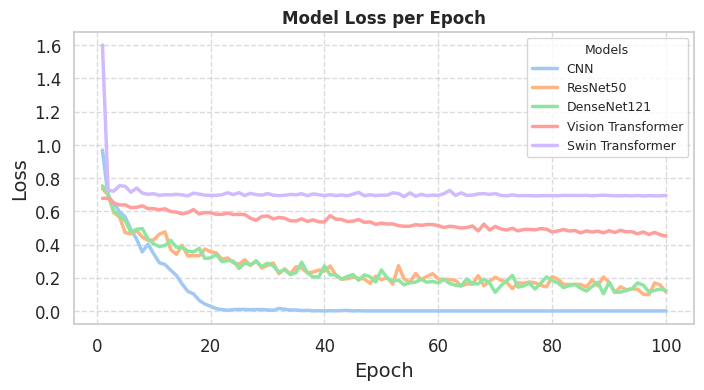

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

CNN = [
    0.9687, 0.6926, 0.6496, 0.5972, 0.5659, 0.4917, 0.4327, 0.3557, 0.4026, 0.3444,
    0.2902, 0.2795, 0.2453, 0.2138, 0.1622, 0.1180, 0.1029, 0.0638, 0.0413, 0.0280,
    0.0135, 0.0082, 0.0043, 0.0084, 0.0092, 0.0094, 0.0074, 0.0085, 0.0083, 0.0062,
    0.0043, 0.0144, 0.0106, 0.0052, 0.0059, 0.0019, 0.0040, 0.0004, 0.0017, 0.0002,
    0.0018, 0.0004, 0.0025, 0.0031, 0.0002, 0.0016, 0.0002, 0.0002, 0.0002, 0.0002,
    0.0002, 0.0002, 0.0001, 0.0001, 0.0000, 0.0001, 0.0000, 0.0000, 0.0001, 0.0001,
    0.0000, 0.0001, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
    0.0000, 0.0001, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
    0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0001, 0.0000, 0.0001, 0.0000, 0.0000,
    0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
]

ResNet50 = [
    0.7356, 0.6996, 0.5914, 0.5657, 0.4719, 0.4644, 0.4847, 0.4451, 0.4252, 0.4279,
    0.4624, 0.4766, 0.3688, 0.3410, 0.3947, 0.3308, 0.3336, 0.3318, 0.3732, 0.3569,
    0.3489, 0.3109, 0.3193, 0.2894, 0.2817, 0.3081, 0.2732, 0.3024, 0.2591, 0.2744,
    0.2886, 0.2241, 0.2538, 0.2224, 0.2662, 0.2571, 0.2305, 0.2339, 0.2463, 0.2398,
    0.2712, 0.2134, 0.1908, 0.1943, 0.2046, 0.1969, 0.1923, 0.1670, 0.2101, 0.1879,
    0.2004, 0.1613, 0.2729, 0.1922, 0.1728, 0.2255, 0.1885, 0.2082, 0.2242, 0.1918,
    0.1905, 0.1876, 0.1846, 0.1499, 0.1627, 0.1616, 0.2124, 0.1520, 0.1790, 0.2029,
    0.1860, 0.1726, 0.1345, 0.1688, 0.1669, 0.1746, 0.1693, 0.1533, 0.1455, 0.2063,
    0.1915, 0.1601, 0.1595, 0.1602, 0.1593, 0.1450, 0.1869, 0.1518, 0.2047, 0.1718,
    0.1105, 0.1453, 0.1278, 0.1329, 0.1311, 0.1003, 0.0986, 0.1690, 0.1558, 0.1139
]

DenseNet121 = [
    0.7531, 0.7065, 0.6018, 0.5750, 0.5441, 0.4730, 0.4917, 0.4962, 0.4334, 0.4041,
    0.3878, 0.3949, 0.4250, 0.3838, 0.3819, 0.3606, 0.3554, 0.3778, 0.3159, 0.3193,
    0.3399, 0.2968, 0.3042, 0.2999, 0.2559, 0.2883, 0.2784, 0.2984, 0.2680, 0.2872,
    0.2718, 0.2340, 0.2483, 0.2191, 0.2304, 0.2936, 0.2298, 0.2052, 0.2040, 0.2715,
    0.2180, 0.2176, 0.1913, 0.2072, 0.2194, 0.1848, 0.2175, 0.2064, 0.1745, 0.2470,
    0.1990, 0.1809, 0.1854, 0.1575, 0.1701, 0.1734, 0.1909, 0.1726, 0.1773, 0.1690,
    0.1896, 0.1651, 0.1551, 0.1512, 0.1925, 0.1647, 0.1629, 0.1919, 0.1683, 0.1122,
    0.1522, 0.1807, 0.2142, 0.1435, 0.1513, 0.1674, 0.1321, 0.1676, 0.2051, 0.1828,
    0.1688, 0.1404, 0.1530, 0.1591, 0.1369, 0.1194, 0.1473, 0.1733, 0.1041, 0.1736,
    0.1129, 0.1133, 0.1238, 0.1335, 0.1694, 0.1551, 0.1149, 0.1240, 0.1322, 0.1236
]

Vision_Transformer = [
    0.6779, 0.6784, 0.6506, 0.6383, 0.6389, 0.6219, 0.6241, 0.6332, 0.6165, 0.6163,
    0.6096, 0.6151, 0.5984, 0.5949, 0.5847, 0.5921, 0.6102, 0.5842, 0.5927, 0.5912,
    0.5823, 0.5816, 0.5897, 0.5806, 0.5813, 0.5805, 0.5585, 0.5465, 0.5689, 0.5720,
    0.5548, 0.5632, 0.5586, 0.5429, 0.5422, 0.5549, 0.5394, 0.5487, 0.5366, 0.5361,
    0.5740, 0.5528, 0.5513, 0.5386, 0.5408, 0.5507, 0.5336, 0.5369, 0.5214, 0.5290,
    0.5232, 0.5245, 0.5134, 0.5102, 0.5102, 0.5196, 0.5154, 0.5206, 0.5206, 0.5139,
    0.5028, 0.5099, 0.5060, 0.4992, 0.5022, 0.5120, 0.4820, 0.5229, 0.4874, 0.5089,
    0.4939, 0.4876, 0.4977, 0.4821, 0.4907, 0.4911, 0.4885, 0.4960, 0.4923, 0.4754,
    0.4822, 0.4903, 0.4812, 0.4846, 0.4697, 0.4821, 0.4753, 0.4808, 0.4706, 0.4829,
    0.4728, 0.4858, 0.4760, 0.4770, 0.4648, 0.4759, 0.4604, 0.4731, 0.4591, 0.4505
]

Swin_Transformer = [
    1.6019, 0.7265, 0.7216, 0.7544, 0.7509, 0.7149, 0.7406, 0.7104, 0.7023, 0.7064,
    0.6961, 0.6998, 0.6990, 0.7025, 0.6987, 0.6929, 0.7095, 0.7036, 0.6971, 0.6961,
    0.6959, 0.7002, 0.7115, 0.7005, 0.7120, 0.6949, 0.7082, 0.7005, 0.6975, 0.7068,
    0.6971, 0.6946, 0.6965, 0.7016, 0.6993, 0.7061, 0.6939, 0.7046, 0.7004, 0.6946,
    0.6999, 0.6946, 0.6987, 0.6933, 0.7034, 0.7142, 0.6937, 0.6998, 0.6947, 0.6974,
    0.6970, 0.7112, 0.7073, 0.6881, 0.7110, 0.6905, 0.7025, 0.6940, 0.6978, 0.6960,
    0.7065, 0.7260, 0.6954, 0.7109, 0.6959, 0.6979, 0.7048, 0.7068, 0.7014, 0.7071,
    0.6954, 0.6930, 0.6992, 0.6937, 0.6947, 0.6945, 0.6930, 0.6942, 0.6945, 0.6947,
    0.6936, 0.6961, 0.6954, 0.6957, 0.6953, 0.6963, 0.6933, 0.6957, 0.6970, 0.6950,
    0.6942, 0.6933, 0.6947, 0.6934, 0.6950, 0.6926, 0.6944, 0.6935, 0.6932, 0.6959
]


# Create the DataFrame with each model as a column
loss_df = pd.DataFrame({
    'Epoch': range(1, 101),
    'CNN': CNN,
    'ResNet50': ResNet50,
    'DenseNet121': DenseNet121,
    'Vision Transformer': Vision_Transformer,
    'Swin Transformer': Swin_Transformer
})

# Set up the plot
plt.figure(figsize=(8, 3.8))
sns.set_theme(style="whitegrid")
sns.set_palette("pastel")

# Plot the losses with enhanced visualization
sns.lineplot(data=loss_df, x='Epoch', y='CNN', label='CNN', linewidth=2.5)
sns.lineplot(data=loss_df, x='Epoch', y='ResNet50', label='ResNet50', linewidth=2.5)
sns.lineplot(data=loss_df, x='Epoch', y='DenseNet121', label='DenseNet121', linewidth=2.5)
sns.lineplot(data=loss_df, x='Epoch', y='Vision Transformer', label='Vision Transformer', linewidth=2.5)
sns.lineplot(data=loss_df, x='Epoch', y='Swin Transformer', label='Swin Transformer', linewidth=2.5)

# Additional plot formatting
plt.title('Model Loss per Epoch', fontsize=12, fontweight='bold')
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(title='Models', fontsize=9, title_fontsize='9', loc='upper right')
plt.grid(True, linestyle='--', alpha=0.7)

# # Highlighting the beginning and end of the training
# plt.axvline(x=1, color='grey', linestyle='--', alpha=0.5)
# plt.axvline(x=100, color='grey', linestyle='--', alpha=0.5)

plt.show()

### Acuracy Related Metrics

<ipython-input-15-37fa856db149>:26: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=metrics_df_melted, x='Metric', y='Value', hue='Model', ci=None)


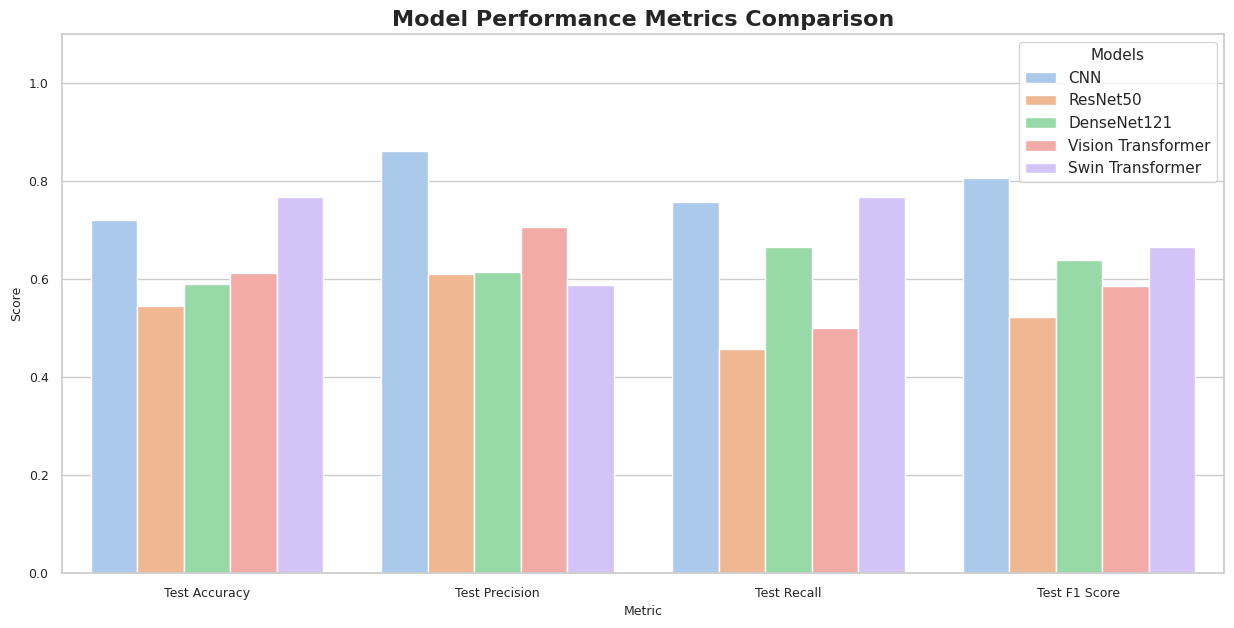

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Metrics data
metrics_data = {
    'Model': ['CNN', 'ResNet50', 'DenseNet121', 'Vision Transformer', 'Swin Transformer'],
    'Test Accuracy': [0.7209, 0.5455, 0.5909, 0.6136, 0.7674],
    'Test Precision': [0.8621, 0.6111, 0.6154, 0.7059, 0.5890],
    'Test Recall': [0.7576, 0.4583, 0.6667, 0.5000, 0.7674],
    'Test F1 Score': [0.8065, 0.5238, 0.6400, 0.5854, 0.6665]
}

# Create DataFrame
metrics_df = pd.DataFrame(metrics_data)

# Melt the DataFrame to have a long-form data for seaborn
metrics_df_melted = metrics_df.melt(id_vars='Model', var_name='Metric', value_name='Value')

# Set up the plot
plt.figure(figsize=(15, 7))
sns.set_theme(style="whitegrid")
sns.set_palette("pastel")

# Create a grouped bar plot
sns.barplot(data=metrics_df_melted, x='Metric', y='Value', hue='Model', ci=None)

# Additional plot formatting
plt.title('Model Performance Metrics Comparison', fontsize=16, fontweight='bold')
plt.xlabel('Metric', fontsize=9)
plt.ylabel('Score', fontsize=9)
plt.xticks(fontsize=9)
plt.yticks(fontsize=9)
plt.legend(title='Models', fontsize=11, title_fontsize='11', loc='upper right')
plt.ylim(0, 1.1)  # Set y-axis limit from 0 to 1.1 for better visibility

plt.show()
